In [49]:
import pandas as pd

data={'order_id':[1001,1002,1003,1004,1005,1006,1007,1008,1009,1010,1011,1012,1013,1014,1015],
      'order_date':['2026-01-01','2026-01-02','2026-01-03','2026-01-04','2026-01-05','2026-01-06','2026-01-07','2026-01-08','2026-01-09','2026-01-10','2026-01-11','2026-01-12','2026-01-13','2026-01-14','2026-01-15'],
      'product':['laptop','mouse','keyboard','mobile','laptop','headphone','mouse','mobile','keyboard','laptop','headphone','mouse','mobile','keyboard','laptop'],
      'category':['electronics','accessories','accessories','electronics','electronics','accessories','accessories','electronics','accessories','electronics','accessories','accessories','electronics','accessories','electronics'],
      'quantity':[2,5,3,1,1,4,6,2,5,1,3,4,2,3,2],
      'unit_price':[50000,500,1000,20000,50000,1500,500,20000,1000,50000,1500,500,20000,1000,50000],
      'customer_city':['bangalore','chennai','mumbai','delhi','bangalore','chennai','delhi','mumbai','bangalore','delhi','chennai','mumbai','bangalore','delhi','chennai'],
      'payment_mode':['UPI','card','cash','UPI','card','cash','UPI','card','cash','UPI','card','cash','UPI','card','UPI']}
df=pd.DataFrame(data)
print(df)

    order_id  order_date    product     category  quantity  unit_price  \
0       1001  2026-01-01     laptop  electronics         2       50000   
1       1002  2026-01-02      mouse  accessories         5         500   
2       1003  2026-01-03   keyboard  accessories         3        1000   
3       1004  2026-01-04     mobile  electronics         1       20000   
4       1005  2026-01-05     laptop  electronics         1       50000   
5       1006  2026-01-06  headphone  accessories         4        1500   
6       1007  2026-01-07      mouse  accessories         6         500   
7       1008  2026-01-08     mobile  electronics         2       20000   
8       1009  2026-01-09   keyboard  accessories         5        1000   
9       1010  2026-01-10     laptop  electronics         1       50000   
10      1011  2026-01-11  headphone  accessories         3        1500   
11      1012  2026-01-12      mouse  accessories         4         500   
12      1013  2026-01-13     mobile  e

In [50]:
print(df.head())
print(df.shape)
print(df.info())
print(df.isnull().sum())

   order_id  order_date   product     category  quantity  unit_price  \
0      1001  2026-01-01    laptop  electronics         2       50000   
1      1002  2026-01-02     mouse  accessories         5         500   
2      1003  2026-01-03  keyboard  accessories         3        1000   
3      1004  2026-01-04    mobile  electronics         1       20000   
4      1005  2026-01-05    laptop  electronics         1       50000   

  customer_city payment_mode  
0     bangalore          UPI  
1       chennai         card  
2        mumbai         cash  
3         delhi          UPI  
4     bangalore         card  
(15, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   order_id       15 non-null     int64 
 1   order_date     15 non-null     object
 2   product        15 non-null     object
 3   category       15 non-null     object
 4   quantity

In [51]:
df['total_sales']=df['quantity']*df['unit_price']
print(df)

    order_id  order_date    product     category  quantity  unit_price  \
0       1001  2026-01-01     laptop  electronics         2       50000   
1       1002  2026-01-02      mouse  accessories         5         500   
2       1003  2026-01-03   keyboard  accessories         3        1000   
3       1004  2026-01-04     mobile  electronics         1       20000   
4       1005  2026-01-05     laptop  electronics         1       50000   
5       1006  2026-01-06  headphone  accessories         4        1500   
6       1007  2026-01-07      mouse  accessories         6         500   
7       1008  2026-01-08     mobile  electronics         2       20000   
8       1009  2026-01-09   keyboard  accessories         5        1000   
9       1010  2026-01-10     laptop  electronics         1       50000   
10      1011  2026-01-11  headphone  accessories         3        1500   
11      1012  2026-01-12      mouse  accessories         4         500   
12      1013  2026-01-13     mobile  e

In [52]:
total_revenue=df['total_sales'].sum()
print("total revenue is : ",total_revenue)

average_order=df['total_sales'].mean()
print("average order value is : ",average_order)


total revenue is :  429000
average order value is :  28600.0


In [53]:
product_sales=df.groupby('product')['quantity'].sum()
print(product_sales)

print("\ntotal no.of products purchased",product_sales.sum())

most_purchased=product_sales.sort_values(ascending=False)
print("\nmost purchased product is : ",most_purchased.index[0])

product
headphone     7
keyboard     11
laptop        6
mobile        5
mouse        15
Name: quantity, dtype: int64

total no.of products purchased 44

most purchased product is :  mouse


In [54]:
revenue_by_product=df.groupby('product')['total_sales'].sum()
print(revenue_by_product)


highest_revenue_product=revenue_by_product.sort_values(ascending=False)
print("\n highest revenue generated product is : ",highest_revenue_product.index[0])

product
headphone     10500
keyboard      11000
laptop       300000
mobile       100000
mouse          7500
Name: total_sales, dtype: int64

 highest revenue generated product is :  laptop


In [55]:
city_revenue=df.groupby('customer_city')['total_sales'].sum()
print("\ncity_revenue")
print(city_revenue)

most_revenue_city=city_revenue.sort_values(ascending=False)
print("most revenue generated city : ",most_revenue_city.index[0])

percentage_of_city_revenue=(city_revenue/total_revenue)*100
print("\npercentage_of_city_revenue")
print(round(percentage_of_city_revenue,2))



city_revenue
customer_city
bangalore    195000
chennai      113000
delhi         76000
mumbai        45000
Name: total_sales, dtype: int64
most revenue generated city :  bangalore

percentage_of_city_revenue
customer_city
bangalore    45.45
chennai      26.34
delhi        17.72
mumbai       10.49
Name: total_sales, dtype: float64


In [56]:
payment_analysis=df['payment_mode'].value_counts()
print(payment_analysis)

payment_percentage=df['payment_mode'].value_counts(normalize=True)*100
print(round(payment_percentage,2))

payment_mode
UPI     6
card    5
cash    4
Name: count, dtype: int64
payment_mode
UPI     40.00
card    33.33
cash    26.67
Name: proportion, dtype: float64


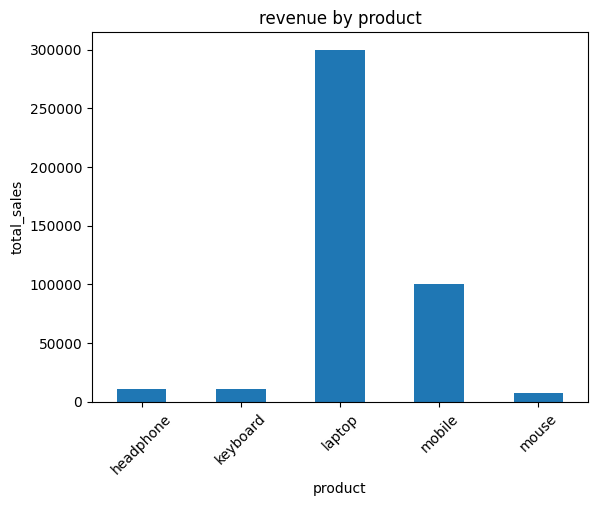

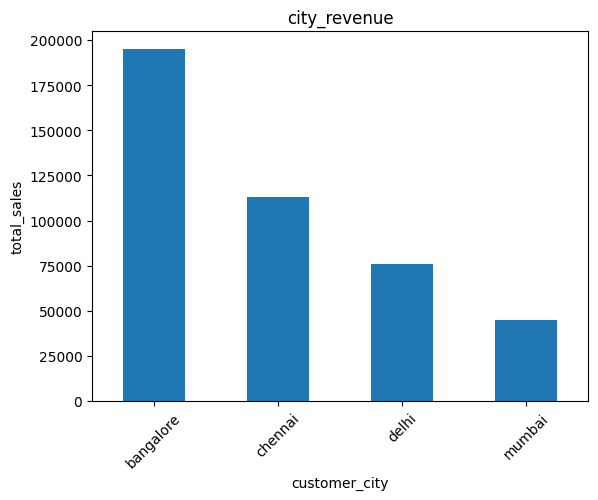

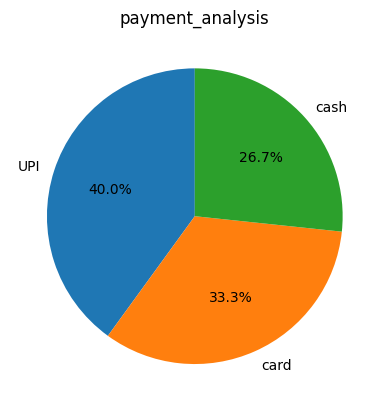

In [57]:
import matplotlib.pyplot as plt
revenue_by_product.plot(kind="bar")
plt.xlabel('product')
plt.ylabel('total_sales')
plt.title('revenue by product')
plt.xticks(rotation=45)
plt.show()


city_revenue.plot(kind="bar")
plt.xlabel('customer_city')
plt.ylabel('total_sales')
plt.title('city_revenue')
plt.xticks(rotation=45)
plt.show()



plt.pie(payment_analysis,labels=payment_analysis.index,autopct='%1.1f%%',startangle=90)
plt.title('payment_analysis')
plt.show()

In [58]:
product_summary=df.groupby('product').agg(total_quantity=('quantity','sum'),total_revenue=('total_sales','sum')).reset_index()
print(product_summary)

     product  total_quantity  total_revenue
0  headphone               7          10500
1   keyboard              11          11000
2     laptop               6         300000
3     mobile               5         100000
4      mouse              15           7500


In [61]:
city_summary = city_revenue.reset_index()

print(city_summary)

  customer_city  total_sales
0     bangalore       195000
1       chennai       113000
2         delhi        76000
3        mumbai        45000


In [63]:
payment_summary=payment_analysis.reset_index()
print(payment_summary)

  payment_mode  count
0          UPI      6
1         card      5
2         cash      4


In [65]:
with pd.ExcelWriter('Ecommerce_sales_report.xlsx')as writer:
  df.to_excel(writer,sheet_name='sales report',index=False)
  product_summary.to_excel(writer,sheet_name='product summary',index=False)
  city_summary.to_excel(writer,sheet_name='city summary',index=False)
  payment_summary.to_excel(writer,sheet_name='payment summary',index=False)
print("excel report exported successfully")

excel report exported successfully


In [66]:
from google.colab import files
files.download('Ecommerce_sales_report.xlsx')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>